# TP Integrador de Aprendizaje Automático · Entrenamiento (Entregas 2 a 4)
**Instituto 57** · Enzo Mellado, Gladys González y Lucas Pardo

**Proyecto:** demanda eléctrica horaria del Gran Buenos Aires (CAMMESA, 2012–2018).
Regresión: estimar `DemGBA` (MW). Clasificación: anticipar `alta_demanda` (la demanda supera el umbral).

Este notebook se ejecuta **de principio a fin** desde la carpeta `notebooks/`:
- **Secciones 1 a 9 (Entrega 2):** preparan el dataset, documentan objetivos y protocolo, y calculan los baselines. Leen `../datos/cammesa_limpio.csv` y generan `../datos/cammesa_preparado.csv`, `../datos/resultados_entrega2.json` y figuras en `../informe/figuras/`.
- **Sección 10 (Entrega 3):** regresión con `DecisionTreeRegressor` y `KNeighborsRegressor`.
- **Secciones 11 y 12 (Entrega 4):** clasificación (`DecisionTreeClassifier`, `KNeighborsClassifier`, `GaussianNB`), comparación de los dos sistemas y guardado de los Pipelines en `../modelos/`.
- **Sección 13:** respuestas a las preguntas del informe.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)
warnings.filterwarnings('ignore')

SEED = 42
ARCHIVO = '../datos/cammesa_limpio.csv'
SALIDA = '../datos'
FIGURAS = '../informe/figuras'
os.makedirs(SALIDA, exist_ok=True)
os.makedirs(FIGURAS, exist_ok=True)
RES = {}   # acá se acumulan los resultados que después usa el informe

## 1. Qué representa cada fila
Cada fila es **una hora** del Gran Buenos Aires (GBA): la demanda eléctrica medida (`DemGBA`, en MW) junto con el clima de esa hora y variables de calendario.

In [2]:
df = pd.read_csv(ARCHIVO, parse_dates=['datetime'])
print('Forma:', df.shape)
print('Período:', df.datetime.min(), '→', df.datetime.max())
print(df.dtypes)
df.head()

Forma: (61368, 18)
Período: 2012-01-01 00:00:00 → 2018-12-31 23:00:00
datetime         datetime64[us]
DemGBA                    int64
Temp                    float64
Holiday                   int64
EMAE                    float64
vy                      float64
vx                      float64
GHI                     float64
Hum                     float64
Pres                    float64
falla_sensor               bool
hora                      int64
dia_semana                int64
mes                       int64
fin_de_semana             int64
viento_vel              float64
split                       str
alta_demanda              int64
dtype: object


,datetime,DemGBA,Temp,Holiday,EMAE,vy,vx,GHI,Hum,Pres,falla_sensor,hora,dia_semana,mes,fin_de_semana,viento_vel,split,alta_demanda
0,2012-01-01 00:00:00,4900,22.7,1,145.95,5.23,5.23,0.0,0.72,1014.3,False,0,6,1,1,7.396337,train,0
1,2012-01-01 01:00:00,4724,22.5,1,145.95,4.27,2.47,0.0,0.72,1014.4,False,1,6,1,1,4.932930,train,0
2,2012-01-01 02:00:00,4584,22.2,1,145.95,2.38,0.64,0.0,0.71,1014.5,False,2,6,1,1,2.464549,train,0
3,2012-01-01 03:00:00,4407,22.0,1,145.95,0.00,0.00,0.0,0.71,1014.6,False,3,6,1,1,0.000000,train,0
4,2012-01-01 04:00:00,4196,21.4,1,145.95,-0.62,1.07,0.0,0.75,1015.2,False,4,6,1,1,1.236649,train,0


## 2. Revisión de calidad: tipos, faltantes, duplicados y valores imposibles

In [3]:
def rachas(s):
    # largo de cada tramo consecutivo de nulos -> {largo: cantidad de tramos}
    n = s.isna().astype(int)
    g = (n.diff().fillna(0) != 0).cumsum()
    largos = n.groupby(g).sum()[n.groupby(g).first() == 1]
    return {int(k): int(v) for k, v in largos.value_counts().sort_index().items()}

esperado = pd.date_range(df.datetime.min(), df.datetime.max(), freq='h')
calidad = {
    'filas': int(len(df)),
    'duplicados_fila_completa': int(df.duplicated().sum()),
    'duplicados_datetime': int(df.datetime.duplicated().sum()),
    'horas_que_faltan_en_la_serie': int(len(esperado.difference(df.datetime))),
    'nulos': {c: int(v) for c, v in df.isna().sum().items() if v > 0},
    'filas_con_falla_sensor': int(df.falla_sensor.sum()),
    'incoherencias_calendario': int(((df.hora != df.datetime.dt.hour) |
                                     (df.mes != df.datetime.dt.month) |
                                     (df.dia_semana != df.datetime.dt.dayofweek) |
                                     (df.fin_de_semana != (df.datetime.dt.dayofweek >= 5).astype(int))).sum()),
    'rachas_nulos_Temp': rachas(df.Temp),
    'rachas_nulos_vx': rachas(df.vx),
    'rachas_nulos_GHI': rachas(df.GHI),
    'viento_vel_igual_a_raiz_vx_vy': bool(np.allclose(np.sqrt(df.vx**2 + df.vy**2).fillna(0), df.viento_vel.fillna(0), atol=1e-3)),
    'EMAE_valores_distintos_por_mes': int(df.groupby([df.datetime.dt.year, 'mes']).EMAE.nunique().max()),
}
imposibles = {
    'Hum fuera de [0, 1]': int(((df.Hum < 0) | (df.Hum > 1)).sum()),
    'GHI negativa': int((df.GHI < 0).sum()),
    'DemGBA <= 0': int((df.DemGBA <= 0).sum()),
    'viento_vel negativa': int((df.viento_vel < 0).sum()),
    'Temp fuera de [-10, 50] °C': int(((df.Temp < -10) | (df.Temp > 50)).sum()),
    'Pres fuera de [900, 1100] hPa': int(((df.Pres < 900) | (df.Pres > 1100)).sum()),
}
calidad['valores_imposibles'] = imposibles
RES['calidad'] = calidad
print(json.dumps(calidad, indent=2, ensure_ascii=False))
print()
print('Los 12 faltantes de Temp/Hum/Pres/vx/vy coinciden con falla_sensor:',
      bool(df.loc[df.falla_sensor, ['Temp','Hum','Pres','vx','vy']].isna().all().all()))
print('Horas con GHI faltante:', int(df.GHI.isna().sum()), '(tramos de 24 h = días completos)')

{
  "filas": 61368,
  "duplicados_fila_completa": 0,
  "duplicados_datetime": 0,
  "horas_que_faltan_en_la_serie": 0,
  "nulos": {
    "Temp": 12,
    "vy": 39,
    "vx": 39,
    "GHI": 335,
    "Hum": 12,
    "Pres": 12,
    "viento_vel": 39
  },
  "filas_con_falla_sensor": 12,
  "incoherencias_calendario": 0,
  "rachas_nulos_Temp": {
    "1": 12
  },
  "rachas_nulos_vx": {
    "1": 12,
    "2": 1,
    "3": 1,
    "4": 3,
    "5": 2
  },
  "rachas_nulos_GHI": {
    "23": 1,
    "24": 10,
    "72": 1
  },
  "viento_vel_igual_a_raiz_vx_vy": true,
  "EMAE_valores_distintos_por_mes": 1,
  "valores_imposibles": {
    "Hum fuera de [0, 1]": 0,
    "GHI negativa": 0,
    "DemGBA <= 0": 0,
    "viento_vel negativa": 0,
    "Temp fuera de [-10, 50] °C": 0,
    "Pres fuera de [900, 1100] hPa": 0
  }
}

Los 12 faltantes de Temp/Hum/Pres/vx/vy coinciden con falla_sensor: True
Horas con GHI faltante: 335 (tramos de 24 h = días completos)


**Lectura de la revisión**

- No hay duplicados ni horas salteadas, y `hora`, `mes`, `dia_semana` y `fin_de_semana` son coherentes con `datetime`.
- No hay valores imposibles en los rangos revisados.
- Faltantes: 12 filas con `falla_sensor` (sin Temp, Hum, Pres ni viento) y 335 horas sin GHI, que corresponden a días completos.
- `viento_vel` es exactamente la raíz de `vx² + vy²`, así que es una variable derivada de las otras dos.
- `EMAE` tiene un único valor por mes: es un indicador mensual repetido en todas las horas.

## 3. Variable numérica, umbral y variable binaria
- **Variable numérica (regresión):** `DemGBA`, demanda horaria del GBA en MW.
- **Umbral:** el percentil 90 de la demanda **calculado solo con el conjunto de entrenamiento** (2012–2016). Se usa solo ese período para que ni validación ni prueba influyan en el criterio.
- **Variable binaria (clasificación):** `alta_demanda = 1` si `DemGBA` supera el umbral.

In [4]:
train_raw = df[df.split == 'train']
UMBRAL = float(train_raw.DemGBA.quantile(0.90))
regla = (df.DemGBA > UMBRAL).astype(int)
coincide = bool((regla == df.alta_demanda).all())
print(f'Umbral (percentil 90 del entrenamiento): {UMBRAL:.0f} MW')
print('La columna alta_demanda coincide con DemGBA > umbral en todas las filas:', coincide)

balance = df.groupby('split').agg(filas=('DemGBA', 'size'), desde=('datetime', 'min'), hasta=('datetime', 'max'),
                                  positivos=('alta_demanda', 'sum'), pct_alta=('alta_demanda', 'mean'))
balance['pct_alta'] = (balance.pct_alta * 100).round(1)
balance = balance.loc[['train', 'valid', 'test']]
RES['umbral'] = UMBRAL
RES['umbral_coincide'] = coincide
RES['balance'] = {k: {'filas': int(v.filas), 'desde': str(v.desde.date()), 'hasta': str(v.hasta.date()),
                      'positivos': int(v.positivos), 'pct_alta': float(v.pct_alta)} for k, v in balance.iterrows()}
RES['balance_total_pct'] = float(round(df.alta_demanda.mean() * 100, 1))
balance

Umbral (percentil 90 del entrenamiento): 7307 MW
La columna alta_demanda coincide con DemGBA > umbral en todas las filas: True


,filas,desde,hasta,positivos,pct_alta
split,,,,,
train,43848,2012-01-01,2016-12-31 23:00:00,4384,10.0
valid,8760,2017-01-01,2017-12-31 23:00:00,956,10.9
test,8760,2018-01-01,2018-12-31 23:00:00,1222,13.9


## 4. Fuga de información
| Columna | Decisión | Motivo |
|---|---|---|
| `DemGBA` | No es predictor | Es la variable objetivo de la regresión. |
| `alta_demanda` | No es predictor | Se deriva directamente de `DemGBA`. |
| `datetime` | No es predictor | Es un identificador temporal; la información útil ya está en `hora`, `mes` y `dia_semana`. |
| `split` | No es predictor | Marca la partición, no describe el fenómeno. |
| `falla_sensor` | No es predictor | Es un indicador de calidad del dato, no algo que se conozca al predecir. |
| `vx`, `vy` | Opcionales | Son redundantes con `viento_vel` (que conserva la intensidad pero no la dirección). |
| `EMAE` | Predictor con cautela | Es mensual y en la práctica se publica con retraso. |
| Clima (`Temp`, `Hum`, `Pres`, `GHI`, `viento_vel`) | Predictores | En producción serían pronósticos, no mediciones. |

No se usan variables rezagadas de la demanda (por ejemplo, la demanda de hace 24 horas), porque la consigna prohíbe que la respuesta aparezca directa o indirectamente entre las entradas.

## 5. Preparación del dataset
1. Faltantes de `Temp`, `Hum`, `Pres`, `vx` y `vy` (tramos de hasta 5 horas): interpolación lineal en el tiempo, con un límite de 6 horas. Después se recalcula `viento_vel`.
2. Faltantes de `GHI` (días completos): se reemplazan por la media de `GHI` de la misma combinación mes-hora, **calculada solo con el entrenamiento**, porque la radiación solar tiene un ciclo diario marcado.
3. Variables derivadas: `temp_confort` (distancia de la temperatura a la temperatura de menor demanda, calculada en entrenamiento), y la hora y el mes en seno y coseno para respetar su carácter circular.

In [5]:
d = df.sort_values('datetime').reset_index(drop=True).copy()
antes = d[['Temp', 'Hum', 'Pres', 'vx', 'vy', 'GHI']].isna().sum()

# 1) clima: interpolación temporal en tramos cortos
clima = ['Temp', 'Hum', 'Pres', 'vx', 'vy']
d[clima] = d[clima].interpolate(method='linear', limit=6, limit_area='inside')
d['viento_vel'] = np.sqrt(d.vx**2 + d.vy**2)

# 2) GHI: climatología mes-hora calculada solo con entrenamiento
clim = d[d.split == 'train'].groupby(['mes', 'hora']).GHI.mean()
m = d.GHI.isna()
d.loc[m, 'GHI'] = [clim.loc[(a, b)] for a, b in zip(d.loc[m, 'mes'], d.loc[m, 'hora'])]

# 3) variables derivadas
tr0 = d[d.split == 'train']
g = tr0.assign(tb=tr0.Temp.round()).groupby('tb').DemGBA.agg(['mean', 'count'])
T_CONFORT = float(g[g['count'] >= 100]['mean'].idxmin())
d['temp_confort'] = (d.Temp - T_CONFORT).abs()
d['hora_sin'] = np.sin(2 * np.pi * d.hora / 24)
d['hora_cos'] = np.cos(2 * np.pi * d.hora / 24)
d['mes_sin'] = np.sin(2 * np.pi * (d.mes - 1) / 12)
d['mes_cos'] = np.cos(2 * np.pi * (d.mes - 1) / 12)

PREDICTORES_BASE = ['Temp', 'Hum', 'Pres', 'GHI', 'viento_vel', 'Holiday', 'EMAE',
                    'hora', 'dia_semana', 'mes', 'fin_de_semana']
PREDICTORES_DERIVADOS = ['temp_confort', 'hora_sin', 'hora_cos', 'mes_sin', 'mes_cos']
FEATS = PREDICTORES_BASE + PREDICTORES_DERIVADOS

cols = ['datetime', 'split'] + FEATS + ['vx', 'vy', 'falla_sensor', 'DemGBA', 'alta_demanda']
prep = d[cols].copy()
for c in ['Temp', 'Hum', 'Pres', 'GHI', 'viento_vel', 'vx', 'vy', 'temp_confort', 'hora_sin', 'hora_cos', 'mes_sin', 'mes_cos']:
    prep[c] = prep[c].round(4)
despues = prep[['Temp', 'Hum', 'Pres', 'GHI', 'vx', 'vy']].isna().sum()
assert prep[FEATS].isna().sum().sum() == 0, 'quedaron faltantes en los predictores'
prep.to_csv(f'{SALIDA}/cammesa_preparado.csv', index=False)

RES['preparacion'] = {'nulos_antes': {k: int(v) for k, v in antes.items()},
                      'nulos_despues': {k: int(v) for k, v in despues.items()},
                      'temp_confort_C': T_CONFORT, 'filas': int(len(prep)), 'columnas': int(prep.shape[1])}
RES['predictores_base'] = PREDICTORES_BASE
RES['predictores_derivados'] = PREDICTORES_DERIVADOS
desc = prep[FEATS + ['DemGBA']].describe().T[['min', 'mean', 'max']]
RES['describe'] = {k: {'min': float(v['min']), 'mean': float(v['mean']), 'max': float(v['max'])} for k, v in desc.iterrows()}
print('Temperatura de menor demanda (entrenamiento):', T_CONFORT, '°C')
print(pd.DataFrame({'antes': antes, 'después': despues}))
print('Dataset preparado:', prep.shape)
desc.round(2)

Temperatura de menor demanda (entrenamiento): 18.0 °C
      antes  después
GHI     335        0
Hum      12        0
Pres     12        0
Temp     12        0
vx       39        0
vy       39        0
Dataset preparado: (61368, 23)


,min,mean,max
Temp,0.40,18.31,37.90
Hum,0.15,0.71,1.00
Pres,993.80,1015.67,1037.90
GHI,0.00,194.42,1136.00
viento_vel,0.00,8.22,39.53
Holiday,0.00,0.05,1.00
EMAE,143.49,146.93,151.36
hora,0.00,11.50,23.00
dia_semana,0.00,3.00,6.00
mes,1.00,6.52,12.00


## 6. Distribuciones y balance de clases
Los gráficos se hacen con el conjunto de entrenamiento, para no mirar validación ni prueba al tomar decisiones.

In [6]:
tr = prep[prep.split == 'train']
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})

# Figura 1: distribución de la demanda y umbral
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(tr.DemGBA, bins=60, color='#8FAADC', edgecolor='white')
ax.axvline(UMBRAL, color='#C00000', lw=2)
ax.text(UMBRAL + 60, ax.get_ylim()[1] * 0.85, f'Umbral: {UMBRAL:,.0f} MW\n(percentil 90)'.replace(',', '.'), color='#C00000')
ax.set_xlabel('Demanda horaria del GBA (MW)'); ax.set_ylabel('Cantidad de horas')
fig.tight_layout(); fig.savefig(f'{FIGURAS}/fig1_distribucion.png', dpi=200); plt.close(fig)

# Figura 2: % de horas de alta demanda por mes y por hora
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
pm = tr.groupby('mes').alta_demanda.mean() * 100
axs[0].bar(pm.index, pm.values, color='#2F5597'); axs[0].set_xticks(range(1, 13))
axs[0].set_xlabel('Mes'); axs[0].set_ylabel('% de horas con alta demanda'); axs[0].set_title('Por mes')
ph = tr.groupby('hora').alta_demanda.mean() * 100
axs[1].bar(ph.index, ph.values, color='#2F5597'); axs[1].set_xticks(range(0, 24, 3))
axs[1].set_xlabel('Hora del día'); axs[1].set_title('Por hora')
fig.tight_layout(); fig.savefig(f'{FIGURAS}/fig2_alta_mes_hora.png', dpi=200); plt.close(fig)

# Figura 3: demanda media mensual y partición temporal
mm = prep.set_index('datetime').DemGBA.resample('MS').mean()
fig, ax = plt.subplots(figsize=(9, 3))
ax.axvspan(pd.Timestamp('2012-01-01'), pd.Timestamp('2017-01-01'), color='#DEEAF6', label='Entrenamiento (2012–2016)')
ax.axvspan(pd.Timestamp('2017-01-01'), pd.Timestamp('2018-01-01'), color='#FFF2CC', label='Validación (2017)')
ax.axvspan(pd.Timestamp('2018-01-01'), pd.Timestamp('2019-01-01'), color='#E2F0D9', label='Prueba (2018)')
ax.plot(mm.index, mm.values, color='#1F3864', lw=1.5)
ax.set_ylabel('Demanda media mensual (MW)'); ax.legend(loc='upper left', fontsize=8, ncol=3, frameon=False)
ax.set_ylim(mm.min() * 0.9, mm.max() * 1.15)
fig.tight_layout(); fig.savefig(f'{FIGURAS}/fig3_particion_temporal.png', dpi=200); plt.close(fig)

RES['alta_por_mes_train'] = {int(k): round(float(v), 1) for k, v in pm.items()}
RES['alta_por_hora_train'] = {int(k): round(float(v), 1) for k, v in ph.items()}
RES['demanda_media_anual'] = {int(k): round(float(v)) for k, v in prep.groupby(prep.datetime.dt.year).DemGBA.mean().items()}
RES['pct_alta_anual'] = {int(k): round(float(v) * 100, 1) for k, v in prep.groupby(prep.datetime.dt.year).alta_demanda.mean().items()}
print('Mes con más horas de alta demanda:', int(pm.idxmax()), f'({pm.max():.1f} %)')
print('Hora con más horas de alta demanda:', int(ph.idxmax()), f'({ph.max():.1f} %)')
print('Demanda media por año:', RES['demanda_media_anual'])

Mes con más horas de alta demanda: 7 (25.9 %)
Hora con más horas de alta demanda: 21 (29.1 %)
Demanda media por año: {2012: 5477, 2013: 5645, 2014: 5646, 2015: 5986, 2016: 6003, 2017: 5798, 2018: 5792}


## 7. Protocolo de evaluación
- **Partición temporal, sin mezclar:** entrenamiento 2012–2016, validación 2017, prueba 2018. Es una serie temporal, así que el modelo se entrena con el pasado y se evalúa con el futuro.
- **Entrenamiento:** ajusta los modelos y calcula los valores de imputación y escalado (los escaladores van dentro de un `Pipeline`).
- **Validación:** sirve para elegir hiperparámetros (profundidad del árbol, valor de k).
- **Prueba:** se usa **una sola vez** al final, con el modelo ya elegido. En esta entrega se informa para los baselines como referencia.
- **Métricas de regresión:** MAE, RMSE y R².
- **Métricas de clasificación:** accuracy, precision, recall, F1 y matriz de confusión, mirando la clase positiva (alta demanda). Con 10–14 % de positivos, la accuracy sola no alcanza.
- **Semilla fija** (`SEED = 42`) para que los resultados se puedan repetir.

## 8. Baselines
- `DummyRegressor` (predice siempre la media del entrenamiento).
- `DummyClassifier` con `most_frequent` (siempre clase 0) y con `stratified` (sortea según la proporción de clases).
- **Referencia adicional (no la exige la consigna):** un baseline estacional que predice la demanda media del entrenamiento para cada combinación de mes, hora y tipo de día (hábil o fin de semana/feriado). Sirve para saber si un modelo con variables climáticas realmente aporta algo más que el calendario.

In [7]:
tr, va, te = [prep[prep.split == s] for s in ['train', 'valid', 'test']]

def met_reg(y, p):
    return {'MAE': float(mean_absolute_error(y, p)), 'RMSE': float(np.sqrt(mean_squared_error(y, p))), 'R2': float(r2_score(y, p))}

def met_clf(y, p):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return {'accuracy': float(accuracy_score(y, p)), 'precision': float(precision_score(y, p, zero_division=0)),
            'recall': float(recall_score(y, p, zero_division=0)), 'f1': float(f1_score(y, p, zero_division=0)),
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}

res_reg, res_clf = {}, {}

# --- DummyRegressor
dr = DummyRegressor(strategy='mean').fit(tr[FEATS], tr.DemGBA)
res_reg['DummyRegressor (media)'] = {'valid': met_reg(va.DemGBA, dr.predict(va[FEATS])), 'test': met_reg(te.DemGBA, dr.predict(te[FEATS]))}

# --- Referencia estacional: media de entrenamiento por (mes, hora, tipo de día)
def clave(x):
    return list(zip(x.mes, x.hora, ((x.fin_de_semana == 1) | (x.Holiday == 1)).astype(int)))
tabla = tr.assign(k=clave(tr)).groupby('k').DemGBA.mean()
media_global = float(tr.DemGBA.mean())
def pred_estacional(x):
    return np.array([tabla.get(k, media_global) for k in clave(x)])
pe_va, pe_te = pred_estacional(va), pred_estacional(te)
res_reg['Referencia estacional (mes × hora × tipo de día)'] = {'valid': met_reg(va.DemGBA, pe_va), 'test': met_reg(te.DemGBA, pe_te)}

# --- DummyClassifier
for nombre, est in [('DummyClassifier (most_frequent)', 'most_frequent'), ('DummyClassifier (stratified)', 'stratified')]:
    dc = DummyClassifier(strategy=est, random_state=SEED).fit(tr[FEATS], tr.alta_demanda)
    res_clf[nombre] = {'valid': met_clf(va.alta_demanda, dc.predict(va[FEATS])), 'test': met_clf(te.alta_demanda, dc.predict(te[FEATS]))}

# --- Referencia: regresión estacional + umbral
res_clf['Referencia estacional + umbral'] = {
    'valid': met_clf(va.alta_demanda, (pe_va > UMBRAL).astype(int)),
    'test': met_clf(te.alta_demanda, (pe_te > UMBRAL).astype(int))}

RES['baseline_regresion'] = res_reg
RES['baseline_clasificacion'] = res_clf

tabla_reg = pd.DataFrame({(n, s): v[s] for n, v in res_reg.items() for s in ['valid', 'test']}).T.round(3)
print('REGRESIÓN'); print(tabla_reg.to_string())
tabla_clf = pd.DataFrame({(n, s): v[s] for n, v in res_clf.items() for s in ['valid', 'test']}).T.round(3)
print('\nCLASIFICACIÓN'); print(tabla_clf.to_string())

REGRESIÓN
                                                             MAE      RMSE     R2
DummyRegressor (media)                           valid   930.671  1165.731 -0.002
                                                 test   1019.467  1269.844 -0.001
Referencia estacional (mes × hora × tipo de día) valid   492.089   667.847  0.671
                                                 test    611.318   757.047  0.644

CLASIFICACIÓN
                                       accuracy  precision  recall     f1      tn     fp      fn     tp
DummyClassifier (most_frequent) valid     0.891      0.000   0.000  0.000  7804.0    0.0   956.0    0.0
                                test      0.861      0.000   0.000  0.000  7538.0    0.0  1222.0    0.0
DummyClassifier (stratified)    valid     0.813      0.100   0.089  0.094  7040.0  764.0   871.0   85.0
                                test      0.792      0.147   0.102  0.121  6814.0  724.0  1097.0  125.0
Referencia estacional + umbral  valid     0.9

In [8]:
with open(f'{SALIDA}/resultados_entrega2.json', 'w', encoding='utf-8') as f:
    json.dump(RES, f, ensure_ascii=False, indent=2)
print('Listo: datos/cammesa_preparado.csv, datos/resultados_entrega2.json e informe/figuras/ generados.')

Listo: datos/cammesa_preparado.csv, datos/resultados_entrega2.json e informe/figuras/ generados.


## 9. Conclusiones de la Entrega 2
- Los baselines marcan el piso a superar: el `DummyRegressor` tiene R² ≈ 0 y el `DummyClassifier` más frecuente tiene accuracy alta (≈ 86–89 %) sin detectar ningún pico (recall 0).
- Las variables de calendario por sí solas ya explican una parte importante de la demanda (referencia estacional); los modelos de las próximas entregas tendrán que mejorarla usando el clima.
- Para la Entrega 3 queda por definir la comparación de árboles y KNN con las variables base y derivadas, y para la Entrega 4 el esquema de costos de falsos positivos y negativos.

---
# Entrega 3 · Regresión

## 10. Regresión de la demanda horaria

### 10.1 Momento de la predicción y predictores
**Momento de la predicción.** Se estima la demanda de una hora futura (la hora a cubrir con generación y reserva) usando el **calendario de esa hora** y el **pronóstico meteorológico para esa hora**. Todas las entradas se conocen antes de que ocurra la hora a predecir.

**Advertencia.** En el entrenamiento se usan las mediciones de clima, no pronósticos. Los resultados son algo optimistas porque no incluyen el error del pronóstico del tiempo.

**Predictores del modelo (10 columnas crudas):** `Temp`, `Hum`, `Pres`, `GHI`, `viento_vel`, `Holiday`, `hora`, `dia_semana`, `mes`, `fin_de_semana`. Dentro del Pipeline se calculan 5 derivadas: `temp_confort`, `hora_sin`, `hora_cos`, `mes_sin`, `mes_cos` (15 variables en total).

**Decisiones que se confirman en la tabla siguiente:**
- **`EMAE` queda afuera.** Se publica con retraso, así que no estaría disponible al predecir, y además el modelo la usa mal (ver tabla).
- **Sin rezagos de demanda.** La consigna prohíbe que la respuesta aparezca directa o indirectamente entre las entradas.
- **Las derivadas van dentro del Pipeline** (`features.py`), para que la aplicación Flask reciba solo datos crudos y calcule exactamente lo mismo que el entrenamiento.

Pipelines de regresión: `derivadas → modelo` para el árbol y `derivadas → StandardScaler → modelo` para KNN. Los hiperparámetros se eligen con la **validación (2017)**.

In [9]:
import sys
sys.path.insert(0, '..')          # para importar features.py desde la raíz del repo
import platform
import joblib, sklearn
from IPython.display import Image, display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from features import BASE, agregar_derivadas, NOMBRES_DERIVADAS

RES34 = {}                         # resultados de las Entregas 3 y 4 para el informe

def guardar(fig, nombre):
    """Guarda la figura en informe/figuras y la muestra en el notebook."""
    ruta = f'{FIGURAS}/{nombre}'
    fig.tight_layout(); fig.savefig(ruta, dpi=150); plt.close(fig)
    display(Image(filename=ruta))

def con_derivadas(modelo, escalar=False):
    """Pipeline: variables derivadas -> (escalado) -> modelo. Recibe solo las columnas de BASE."""
    pasos = [('derivadas', FunctionTransformer(agregar_derivadas))]
    if escalar:
        pasos.append(('escalado', StandardScaler()))
    pasos.append(('modelo', modelo))
    return Pipeline(pasos)

Xtr, Xva, Xte = [x[BASE].to_numpy(float) for x in (tr, va, te)]
ytr, yva, yte = [x.DemGBA.to_numpy() for x in (tr, va, te)]
ytr_c, yva_c, yte_c = [x.alta_demanda.to_numpy() for x in (tr, va, te)]
print('Predictores crudos que recibe el Pipeline:', BASE)
print('Variables derivadas calculadas dentro del Pipeline:', NOMBRES_DERIVADAS)

Predictores crudos que recibe el Pipeline: ['Temp', 'Hum', 'Pres', 'GHI', 'viento_vel', 'Holiday', 'hora', 'dia_semana', 'mes', 'fin_de_semana']
Variables derivadas calculadas dentro del Pipeline: ['temp_confort', 'hora_sin', 'hora_cos', 'mes_sin', 'mes_cos']


### 10.2 Comparación de conjuntos de variables (solo entrenamiento y validación)

In [10]:
# Comparación de conjuntos de variables. Solo usa entrenamiento (ajuste) y validación (comparación).
conjuntos = {
    'Base con EMAE (11)': PREDICTORES_BASE,
    'Base sin EMAE (10)': BASE,
    'Base + derivadas, con EMAE (16)': PREDICTORES_BASE + PREDICTORES_DERIVADOS,
    'Base + derivadas, sin EMAE (15)': BASE + PREDICTORES_DERIVADOS,
}
filas = []
for nombre, cols in conjuntos.items():
    a = min((mean_absolute_error(va.DemGBA, DecisionTreeRegressor(max_depth=k, random_state=SEED)
             .fit(tr[cols], tr.DemGBA).predict(va[cols])), k) for k in [5, 8, 10, 12, 15])
    kn = min((mean_absolute_error(va.DemGBA, Pipeline([('e', StandardScaler()), ('m', KNeighborsRegressor(k))])
              .fit(tr[cols], tr.DemGBA).predict(va[cols])), k) for k in [10, 20, 30, 50])
    filas.append({'Conjunto de variables': nombre, 'Árbol: MAE valid (MW)': a[0], 'Árbol: prof.': a[1],
                  'KNN: MAE valid (MW)': kn[0], 'KNN: k': kn[1]})
tab_vars = pd.DataFrame(filas).set_index('Conjunto de variables')
RES34['comparacion_variables_valid'] = {k: {c: float(v) for c, v in r.items()} for k, r in tab_vars.iterrows()}
tab_vars.round(1)

,Árbol: MAE valid (MW),Árbol: prof.,KNN: MAE valid (MW),KNN: k
Conjunto de variables,,,,
Base con EMAE (11),449.3,8,545.3,30
Base sin EMAE (10),351.4,12,417.4,20
"Base + derivadas, con EMAE (16)",387.1,10,402.1,30
"Base + derivadas, sin EMAE (15)",330.0,12,342.2,20


**Lectura.** Quitar `EMAE` mejora el error de validación en todos los casos: con el árbol baja de 449 a 351 MW (variables base) y de 387 a 330 MW (con derivadas); con KNN baja de 545 a 417 y de 402 a 342 MW. `EMAE` es un valor único por mes, así que funciona como un identificador de período. El modelo lo memoriza con el entrenamiento y falla en 2017, donde toma valores más altos que en cualquiera de los años de entrenamiento (promedio anual 149,7 contra un máximo de 148,0).

Las variables derivadas también ayudan: con el árbol el error baja 6 % (351 → 330 MW) y con KNN baja 18 % (417 → 342 MW), porque `temp_confort` captura la forma de U entre temperatura y demanda. **Conjunto elegido:** base sin `EMAE` más derivadas (15 variables).

### 10.3 `DecisionTreeRegressor`: comparación de profundidades

In [11]:
PROFUNDIDADES = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30]
filas, arboles = [], {}
for p in PROFUNDIDADES:
    m = con_derivadas(DecisionTreeRegressor(max_depth=p, random_state=SEED)).fit(Xtr, ytr)
    arboles[p] = m
    mt, mv = met_reg(ytr, m.predict(Xtr)), met_reg(yva, m.predict(Xva))
    filas.append({'profundidad': p, 'MAE train': mt['MAE'], 'MAE valid': mv['MAE'],
                  'RMSE valid': mv['RMSE'], 'R2 valid': mv['R2']})
tab_arbol = pd.DataFrame(filas).set_index('profundidad')
P_OPT = int(tab_arbol['MAE valid'].idxmin())
RES34['regresion_arbol_valid'] = {int(p): {k: float(v) for k, v in r.items()} for p, r in tab_arbol.iterrows()}
print(f'Profundidad elegida con validación: {P_OPT}')
tab_arbol.round({'MAE train': 1, 'MAE valid': 1, 'RMSE valid': 1, 'R2 valid': 3})

Profundidad elegida con validación: 12


,MAE train,MAE valid,RMSE valid,R2 valid
profundidad,,,,
2,708.1,717.7,912.4,0.386
3,631.2,642.2,819.3,0.505
4,550.6,558.5,725.5,0.612
5,490.8,492.8,639.1,0.699
6,439.8,448.5,580.5,0.752
8,359.4,373.1,491.1,0.822
10,298.5,331.0,446.6,0.853
12,242.7,330.0,449.5,0.851
15,149.9,354.2,487.2,0.825


### 10.4 `KNeighborsRegressor` con `StandardScaler` dentro del Pipeline: comparación de k

In [12]:
KS = [1, 3, 5, 10, 15, 20, 30, 50, 75, 100]
filas, knns = [], {}
for k in KS:
    m = con_derivadas(KNeighborsRegressor(n_neighbors=k), escalar=True).fit(Xtr, ytr)
    knns[k] = m
    mt, mv = met_reg(ytr, m.predict(Xtr)), met_reg(yva, m.predict(Xva))
    filas.append({'k': k, 'MAE train': mt['MAE'], 'MAE valid': mv['MAE'],
                  'RMSE valid': mv['RMSE'], 'R2 valid': mv['R2']})
tab_knn = pd.DataFrame(filas).set_index('k')
K_OPT = int(tab_knn['MAE valid'].idxmin())
RES34['regresion_knn_valid'] = {int(k): {c: float(v) for c, v in r.items()} for k, r in tab_knn.iterrows()}
print(f'k elegido con validación: {K_OPT}')
tab_knn.round({'MAE train': 1, 'MAE valid': 1, 'RMSE valid': 1, 'R2 valid': 3})

k elegido con validación: 15


,MAE train,MAE valid,RMSE valid,R2 valid
k,,,,
1,0.0,440.5,591.3,0.742
3,123.6,386.4,522.7,0.799
5,184.4,363.1,491.7,0.822
10,241.7,344.8,467.3,0.839
15,266.1,341.5,460.6,0.844
20,281.1,342.2,459.5,0.844
30,299.0,344.9,462.2,0.843
50,319.1,350.8,470.6,0.837
75,333.9,358.8,482.4,0.828


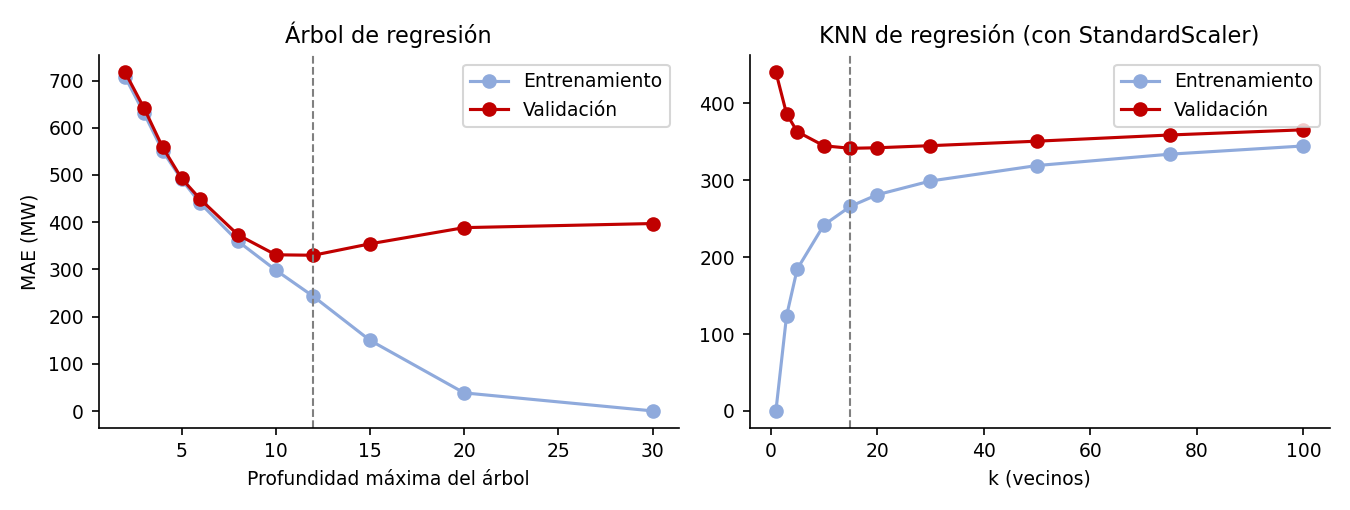

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
axs[0].plot(tab_arbol.index, tab_arbol['MAE train'], 'o-', color='#8FAADC', label='Entrenamiento')
axs[0].plot(tab_arbol.index, tab_arbol['MAE valid'], 'o-', color='#C00000', label='Validación')
axs[0].axvline(P_OPT, color='gray', ls='--', lw=1)
axs[0].set_xlabel('Profundidad máxima del árbol'); axs[0].set_ylabel('MAE (MW)'); axs[0].set_title('Árbol de regresión'); axs[0].legend()
axs[1].plot(tab_knn.index, tab_knn['MAE train'], 'o-', color='#8FAADC', label='Entrenamiento')
axs[1].plot(tab_knn.index, tab_knn['MAE valid'], 'o-', color='#C00000', label='Validación')
axs[1].axvline(K_OPT, color='gray', ls='--', lw=1)
axs[1].set_xlabel('k (vecinos)'); axs[1].set_title('KNN de regresión (con StandardScaler)'); axs[1].legend()
guardar(fig, 'fig4_curvas_hiperparametros.png')

**Lectura.**
- **Árbol:** con poca profundidad subajusta (MAE de 718 MW con profundidad 2). A partir de 12 el error de entrenamiento sigue bajando (243 → 0,4 MW) mientras el de validación sube (330 → 397 MW): sobreajuste. El mínimo de validación es la profundidad 12 (330,0 MW); la 10 queda prácticamente empatada (331,0 MW) y con menos brecha entre entrenamiento y validación.
- **KNN:** con k = 1 memoriza el entrenamiento (error 0 en train y 440 MW en validación). El mínimo está en k = 15 (341,5 MW) y con k ≥ 50 el modelo se vuelve demasiado suave.
- Se aplica la regla definida de antemano, el menor MAE de validación.

### 10.5 Comparación contra los baselines
La elección entre árbol y KNN se hace **solo con el MAE de validación**. La prueba (2018) se informa después, para todos los modelos, sin usarla para decidir nada.

In [14]:
def fila_reg(nombre, p_va, p_te):
    v, t = met_reg(yva, p_va), met_reg(yte, p_te)
    return {'Modelo': nombre, 'MAE valid': v['MAE'], 'RMSE valid': v['RMSE'], 'R2 valid': v['R2'],
            'MAE test': t['MAE'], 'RMSE test': t['RMSE'], 'R2 test': t['R2']}

reg_arbol, reg_knn = arboles[P_OPT], knns[K_OPT]
nom_arbol, nom_knn = f'DecisionTreeRegressor (prof. {P_OPT})', f'KNeighborsRegressor (k={K_OPT}, escalado)'
tab_reg = pd.DataFrame([
    fila_reg('DummyRegressor (media)', dr.predict(va[FEATS]), dr.predict(te[FEATS])),
    fila_reg('Referencia estacional', pe_va, pe_te),
    fila_reg(nom_arbol, reg_arbol.predict(Xva), reg_arbol.predict(Xte)),
    fila_reg(nom_knn, reg_knn.predict(Xva), reg_knn.predict(Xte)),
]).set_index('Modelo')

# La elección se hizo solo con el MAE de validación.
if tab_reg.loc[nom_arbol, 'MAE valid'] <= tab_reg.loc[nom_knn, 'MAE valid']:
    REG, NOM_REG = reg_arbol, nom_arbol
else:
    REG, NOM_REG = reg_knn, nom_knn
RES34['regresion_comparacion'] = {m: {c: float(v) for c, v in r.items()} for m, r in tab_reg.iterrows()}
RES34['regresor_elegido'] = NOM_REG
print('Regresor elegido (menor MAE de validación):', NOM_REG)
mae_te = tab_reg.loc[NOM_REG, 'MAE test']
print(f'MAE test = {mae_te:.0f} MW = {mae_te / te.DemGBA.mean() * 100:.1f} % de la demanda media y '
      f'{mae_te / UMBRAL * 100:.1f} % del umbral')
tab_reg.round({'MAE valid': 1, 'RMSE valid': 1, 'R2 valid': 3, 'MAE test': 1, 'RMSE test': 1, 'R2 test': 3})

Regresor elegido (menor MAE de validación): DecisionTreeRegressor (prof. 12)
MAE test = 413 MW = 7.1 % de la demanda media y 5.7 % del umbral


,MAE valid,RMSE valid,R2 valid,MAE test,RMSE test,R2 test
Modelo,,,,,,
DummyRegressor (media),930.7,1165.7,-0.002,1019.5,1269.8,-0.001
Referencia estacional,492.1,667.8,0.671,611.3,757.0,0.644
DecisionTreeRegressor (prof. 12),330.0,449.5,0.851,412.9,530.3,0.825
"KNeighborsRegressor (k=15, escalado)",341.5,460.6,0.844,413.2,513.6,0.836


**Lectura.**
- **Los dos modelos superan a los baselines.** En prueba, el regresor elegido tiene un MAE de 413 MW, contra 1.019 MW del `DummyRegressor` (−59 %) y 611 MW de la referencia estacional (−32 %). El R² sube de −0,001 y 0,644 a 0,825.
- **La mejora sobre la referencia estacional se mantiene entre validación y prueba** (−33 % y −32 %). El error absoluto sube de 330 a 413 MW porque 2018 es un año más difícil para todos los modelos, incluidos los baselines.
- **Árbol y KNN quedan prácticamente empatados en prueba** (413 MW los dos; el KNN tiene RMSE y R² algo mejores). Se mantiene la decisión tomada con validación (árbol de profundidad 12). No se cambia el modelo después de ver la prueba.
- **Qué significa el MAE.** Un MAE de 413 MW es el 7,1 % de la demanda media de 2018 y el 5,7 % del umbral: en promedio la estimación se desvía esa cantidad de la demanda real. Una hora estimada a menos de unos 400 MW del umbral cae en una zona de incertidumbre.

### 10.6 Residuos y errores importantes (prueba, solo descriptivo)

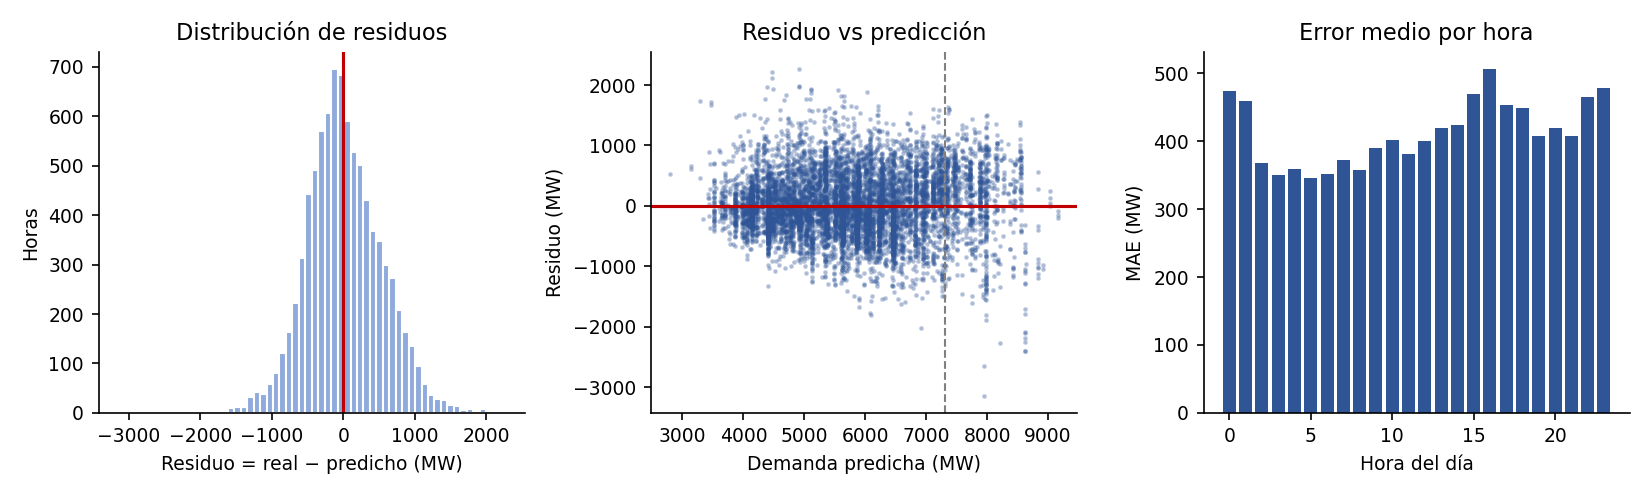

Sesgo medio (real − predicho): 16.0 MW
Error en las horas con demanda real sobre el umbral: MAE = 562 MW (sesgo 470 MW)
MAE por mes: {1: 463, 2: 474, 3: 365, 4: 299, 5: 286, 6: 458, 7: 559, 8: 385, 9: 356, 10: 393, 11: 429, 12: 491}


,horas,MAE (MW)
DemGBA,,
a menos de 300 MW del umbral,712,479.8
entre 300 y 800 MW,1195,507.1
a más de 800 MW,6853,389.6


,Fecha y hora,Real (MW),Predicho (MW),Error (MW),Temp (°C),Hora,Feriado
58959,2018-09-22 15:00:00,4799,7953.0,-3154.0,30.2,15,0
58962,2018-09-22 18:00:00,5302,7953.0,-2651.0,29.4,18,0
54568,2018-03-23 16:00:00,6235,8632.0,-2397.0,30.0,16,0
54567,2018-03-23 15:00:00,6237,8632.0,-2395.0,29.6,15,0
53754,2018-02-17 18:00:00,7181,4909.9,2271.1,30.8,18,0
61221,2018-12-25 21:00:00,5944,8206.4,-2262.4,28.0,21,1
54325,2018-03-13 13:00:00,6376,8632.0,-2256.0,29.1,13,0
57642,2018-07-29 18:00:00,6673,4465.0,2208.0,11.4,18,0
54326,2018-03-13 14:00:00,6450,8632.0,-2182.0,29.2,14,0
57637,2018-07-29 13:00:00,6578,4465.0,2113.0,10.8,13,0


In [15]:
# Análisis descriptivo de errores sobre prueba. No se cambia ningún modelo a partir de esto.
pred_te = REG.predict(Xte)
err = te.assign(pred=pred_te, error=yte - pred_te)
err['abs_error'] = err.error.abs()

fig, axs = plt.subplots(1, 3, figsize=(11, 3.3))
axs[0].hist(err.error, bins=60, color='#8FAADC', edgecolor='white')
axs[0].axvline(0, color='#C00000'); axs[0].set_xlabel('Residuo = real − predicho (MW)'); axs[0].set_ylabel('Horas')
axs[0].set_title('Distribución de residuos')
axs[1].scatter(err.pred, err.error, s=2, alpha=0.25, color='#2F5597')
axs[1].axhline(0, color='#C00000'); axs[1].axvline(UMBRAL, color='gray', ls='--', lw=1)
axs[1].set_xlabel('Demanda predicha (MW)'); axs[1].set_ylabel('Residuo (MW)'); axs[1].set_title('Residuo vs predicción')
ph = err.groupby('hora').abs_error.mean(); pm = err.groupby('mes').abs_error.mean()
axs[2].bar(ph.index, ph.values, color='#2F5597'); axs[2].set_xlabel('Hora del día'); axs[2].set_ylabel('MAE (MW)')
axs[2].set_title('Error medio por hora')
guardar(fig, 'fig5_residuos.png')

print('Sesgo medio (real − predicho):', round(float(err.error.mean()), 1), 'MW')
print('Error en las horas con demanda real sobre el umbral: MAE =', round(float(err[err.alta_demanda == 1].abs_error.mean())),
      'MW (sesgo', round(float(err[err.alta_demanda == 1].error.mean())), 'MW)')
print('MAE por mes:', {int(k): int(round(v)) for k, v in pm.items()})
RES34['sesgo_test_MW'] = float(err.error.mean())
RES34['mae_test_en_picos_MW'] = float(err[err.alta_demanda == 1].abs_error.mean())
RES34['mae_test_por_hora'] = {int(k): float(v) for k, v in ph.items()}
RES34['mae_test_por_mes'] = {int(k): float(v) for k, v in pm.items()}

dist = (err.DemGBA - UMBRAL).abs()
banda = pd.cut(dist, [-1, 300, 800, np.inf], labels=['a menos de 300 MW del umbral', 'entre 300 y 800 MW', 'a más de 800 MW'])
tab_banda = err.groupby(banda, observed=True).abs_error.agg(['count', 'mean']).rename(columns={'count': 'horas', 'mean': 'MAE (MW)'})
RES34['mae_por_cercania_umbral'] = {k: {'horas': int(r['horas']), 'MAE': float(r['MAE (MW)'])} for k, r in tab_banda.iterrows()}
display(tab_banda.round(1))
top = err.nlargest(10, 'abs_error')[['datetime', 'DemGBA', 'pred', 'error', 'Temp', 'hora', 'Holiday']]
top.columns = ['Fecha y hora', 'Real (MW)', 'Predicho (MW)', 'Error (MW)', 'Temp (°C)', 'Hora', 'Feriado']
RES34['peores_errores_regresion_test'] = [{**{k: (str(v) if k == 'Fecha y hora' else float(v)) for k, v in r.items()}} for _, r in top.iterrows()]
top.round(1)

**Lectura.**
- **Sin sesgo global.** El residuo medio es de +16 MW y el histograma es simétrico y centrado en cero.
- **Menos precisión justo donde importa.** En las horas con demanda real sobre el umbral el MAE sube a 562 MW y el residuo medio es de +470 MW: el modelo subestima los picos. El error también es mayor cerca del umbral (480–507 MW dentro de 800 MW del umbral, contra 390 MW más lejos). Los valores extremos son los más difíciles de estimar.
- **Por hora y mes.** El error medio es mayor a las 16 h y a las 23–0 h, y en julio (559 MW) y diciembre (491 MW), meses de mayor demanda.
- **Peores errores.** 8 de los 10 mayores errores ocurren con 28–31 °C, y los otros 2 con 11 °C. En muchos casos el modelo predice un valor muy alto para un día en que la demanda real fue mucho menor (p. ej. 22/09/2018 15 h: real 4.799 MW, predicho 7.953 MW).
- **Hipótesis a verificar** (los datos no permiten confirmarlas): días atípicos que `Holiday` no marca (puentes, fines de semana largos) y la inercia del calor acumulado de días anteriores, que el modelo no ve.

### 10.7 Regresor seleccionado
**`DecisionTreeRegressor` de profundidad 12** dentro de un Pipeline (derivadas → árbol), con MAE de validación de 330 MW y de prueba de 413 MW. Se guarda en `../modelos/regresor.joblib` (sección 12.6).

**Mejoras posibles (fuera del alcance de esta entrega):** variables de clima de horas o días previos (no son la respuesta, pero hay que verificar que estén disponibles al predecir) y un calendario de días no laborables más completo.

---
# Entrega 4 · Clasificación e integración

## 11. Clasificación de alta demanda

### 11.1 Esquema de costos
Se usan **unidades relativas**: el costo de un falso positivo vale 1 y el de un falso negativo vale 5. No son costos reales en pesos; es un supuesto de trabajo, y se analiza su sensibilidad en la sección 12.2.

| Error | Qué significa en el problema | Consecuencia | Costo relativo |
|---|---|---|---|
| **Falso positivo (FP)** | Se avisa alta demanda y no ocurre | Se activa generación o reserva adicional sin necesidad | 1 |
| **Falso negativo (FN)** | Ocurre alta demanda y no se avisa | Pico sin cobertura: generación de emergencia más cara, riesgo de cortes | 5 |

**Criterio.** Un pico no anticipado es más grave que una reserva activada de más, porque el FP tiene un costo acotado (combustible y arranque de unidades) y el FN puede comprometer el suministro. La proporción de 5 a 1 es una estimación provisoria. Para reemplazarla por un valor real habría que usar los costos de la reserva y de la energía no suministrada de CAMMESA. Ese dato no está en el dataset.

**Cómo se usa el costo.** (1) Los hiperparámetros del clasificador se eligen por el **costo de validación** (FP + 5 × FN), con desempate por F1. (2) En el árbol se prueba además `class_weight` con pesos 1:5, que traslada el esquema de costos al entrenamiento.

In [16]:
# Esquema de costos (unidades relativas; ver la justificación arriba).
COSTO_FP = 1.0     # alerta que no era necesaria: se activa reserva de más
COSTO_FN = 5.0     # pico no anticipado: sin reserva cuando se necesitaba

def costo(m, c_fn=None):
    c_fn = COSTO_FN if c_fn is None else c_fn
    return COSTO_FP * m['fp'] + c_fn * m['fn']

def fila_clf(nombre, mv, mt):
    return {'Modelo': nombre,
            'Accuracy valid': mv['accuracy'], 'Precision valid': mv['precision'], 'Recall valid': mv['recall'],
            'F1 valid': mv['f1'], 'FP valid': mv['fp'], 'FN valid': mv['fn'], 'Costo valid': costo(mv),
            'Accuracy test': mt['accuracy'], 'Precision test': mt['precision'], 'Recall test': mt['recall'],
            'F1 test': mt['f1'], 'FP test': mt['fp'], 'FN test': mt['fn'], 'Costo test': costo(mt)}

def elegir(tabla):
    """Mejor fila por costo de validación (desempate: mayor F1 de validación)."""
    return tabla.sort_values(['Costo valid', 'F1 valid'], ascending=[True, False]).index[0]

### 11.2 `DecisionTreeClassifier`: profundidades, con y sin pesos de clase

In [17]:
PESOS = {'sin pesos': None, 'pesos 1:5': {0: 1, 1: COSTO_FN}}
PROF_C = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20]
filas, arb_c = [], {}
for nombre_w, w in PESOS.items():
    for p in PROF_C:
        m = con_derivadas(DecisionTreeClassifier(max_depth=p, class_weight=w, random_state=SEED)).fit(Xtr, ytr_c)
        arb_c[(nombre_w, p)] = m
        mv = met_clf(yva_c, m.predict(Xva))
        filas.append({'pesos': nombre_w, 'profundidad': p, 'Accuracy': mv['accuracy'], 'Precision': mv['precision'],
                      'Recall': mv['recall'], 'F1': mv['f1'], 'FP': mv['fp'], 'FN': mv['fn'], 'Costo valid': costo(mv)})
tab_arbol_c = pd.DataFrame(filas).set_index(['pesos', 'profundidad'])
ARB_C_OPT = tab_arbol_c.sort_values(['Costo valid', 'F1'], ascending=[True, False]).index[0]
RES34['clasificacion_arbol_valid'] = {f'{a}|{b}': {c: float(v) for c, v in r.items()} for (a, b), r in tab_arbol_c.iterrows()}
print('Árbol elegido con validación (pesos, profundidad):', ARB_C_OPT)
tab_arbol_c.round({'Accuracy': 3, 'Precision': 3, 'Recall': 3, 'F1': 3, 'Costo valid': 0})

Árbol elegido con validación (pesos, profundidad): ('pesos 1:5', np.int64(8))


Accuracy  Precision  Recall     F1    FP   FN  \
pesos     profundidad                                                  
sin pesos 2               0.905      0.687   0.234  0.349   102  732   
          3               0.917      0.692   0.434  0.533   185  541   
          4               0.924      0.802   0.407  0.540    96  567   
          5               0.936      0.832   0.520  0.640   100  459   
          6               0.933      0.848   0.468  0.603    80  509   
          8               0.946      0.829   0.640  0.723   126  344   
          10              0.945      0.799   0.668  0.728   161  317   
          12              0.941      0.783   0.632  0.699   167  352   
          15              0.934      0.746   0.595  0.662   194  387   
          20              0.931      0.724   0.596  0.654   217  386   
pesos 1:5 2               0.849      0.385   0.643  0.482   982  341   
          3               0.861      0.426   0.792  0.554  1021  199   
          4               0.874      0.459   0.838  0.593   946  155   
          5               0.878      0.467   0.857  0.604   936  137   
          6               0.926      0.616   0.851  0.715   508  142   
          8               0.934      0.648   0.860  0.739   446  134   
          10              0.937      0.667   0.846  0.746   404  147   
          12              0.939      0.690   0.809  0.744   348  183   
          15              0.941      0.732   0.727  0.729   255  261   
          20              0.934      0.749   0.596  0.664   191  386   

                       Costo valid  
pesos     profundidad               
sin pesos 2                 3762.0  
          3                 2890.0  
          4                 2931.0  
          5                 2395.0  
          6                 2625.0  
          8                 1846.0  
          10                1746.0  
          12                1927.0  
          15                2129.0  
          20                2147.0  
pesos 1:5 2                 2687.0  
          3                 2016.0  
          4                 1721.0  
          5                 1621.0  
          6                 1218.0  
          8                 1116.0  
          10                1139.0  
          12                1263.0  
          15                1560.0  
          20                2121.0

### 11.3 `KNeighborsClassifier` con `StandardScaler` dentro del Pipeline

In [18]:
filas, knn_c = [], {}
for k in KS:
    m = con_derivadas(KNeighborsClassifier(n_neighbors=k), escalar=True).fit(Xtr, ytr_c)
    knn_c[k] = m
    mv = met_clf(yva_c, m.predict(Xva))
    filas.append({'k': k, 'Accuracy': mv['accuracy'], 'Precision': mv['precision'], 'Recall': mv['recall'],
                  'F1': mv['f1'], 'FP': mv['fp'], 'FN': mv['fn'], 'Costo valid': costo(mv)})
tab_knn_c = pd.DataFrame(filas).set_index('k')
K_C_OPT = int(tab_knn_c.sort_values(['Costo valid', 'F1'], ascending=[True, False]).index[0])
RES34['clasificacion_knn_valid'] = {int(k): {c: float(v) for c, v in r.items()} for k, r in tab_knn_c.iterrows()}
print('k elegido con validación:', K_C_OPT)
tab_knn_c.round({'Accuracy': 3, 'Precision': 3, 'Recall': 3, 'F1': 3, 'Costo valid': 0})

k elegido con validación: 15


,Accuracy,Precision,Recall,F1,FP,FN,Costo valid
k,,,,,,,
1,0.927,0.699,0.581,0.634,239,401,2244.0
3,0.934,0.754,0.582,0.657,181,400,2181.0
5,0.937,0.783,0.584,0.669,155,398,2145.0
10,0.941,0.864,0.540,0.665,81,440,2281.0
15,0.944,0.853,0.585,0.694,96,397,2081.0
20,0.942,0.867,0.550,0.673,81,430,2231.0
30,0.942,0.871,0.552,0.676,78,428,2218.0
50,0.944,0.888,0.554,0.683,67,426,2197.0
75,0.942,0.877,0.543,0.671,73,437,2258.0


### 11.4 `GaussianNB`

In [19]:
filas, gnbs = [], {}
for vs in [1e-9, 1e-6, 1e-4, 1e-2, 1e-1, 1.0]:
    m = con_derivadas(GaussianNB(var_smoothing=vs)).fit(Xtr, ytr_c)
    gnbs[vs] = m
    mv = met_clf(yva_c, m.predict(Xva))
    filas.append({'var_smoothing': vs, 'Accuracy': mv['accuracy'], 'Precision': mv['precision'], 'Recall': mv['recall'],
                  'F1': mv['f1'], 'FP': mv['fp'], 'FN': mv['fn'], 'Costo valid': costo(mv)})
tab_gnb = pd.DataFrame(filas).set_index('var_smoothing')
VS_OPT = float(tab_gnb.sort_values(['Costo valid', 'F1'], ascending=[True, False]).index[0])
RES34['clasificacion_gnb_valid'] = {str(k): {c: float(v) for c, v in r.items()} for k, r in tab_gnb.iterrows()}
print('var_smoothing elegido con validación:', VS_OPT)
tab_gnb.round({'Accuracy': 3, 'Precision': 3, 'Recall': 3, 'F1': 3, 'Costo valid': 0})

var_smoothing elegido con validación: 1e-09


,Accuracy,Precision,Recall,F1,FP,FN,Costo valid
var_smoothing,,,,,,,
1.000000e-09,0.888,0.490,0.657,0.561,654,328,2294.0
1.000000e-06,0.899,0.539,0.532,0.536,436,447,2671.0
1.000000e-04,0.903,0.604,0.318,0.417,199,652,3459.0
1.000000e-02,0.891,0.000,0.000,0.000,0,956,4780.0
1.000000e-01,0.891,0.000,0.000,0.000,0,956,4780.0
1.000000e+00,0.891,0.000,0.000,0.000,0,956,4780.0


### 11.5 Comparación de clasificadores y baselines
Se elige el clasificador con el menor costo de validación. La prueba se muestra después, sin usarla para decidir.

In [20]:
m_arb, m_knn, m_gnb = arb_c[ARB_C_OPT], knn_c[K_C_OPT], gnbs[VS_OPT]
nom_arb_c = f'DecisionTreeClassifier (prof. {ARB_C_OPT[1]}, {ARB_C_OPT[0]})'
nom_knn_c = f'KNeighborsClassifier (k={K_C_OPT}, escalado)'
nom_gnb_c = f'GaussianNB (var_smoothing={VS_OPT:g})'
dmf, dst, dse = (res_clf['DummyClassifier (most_frequent)'], res_clf['DummyClassifier (stratified)'],
                 res_clf['Referencia estacional + umbral'])
tab_clf = pd.DataFrame([
    fila_clf('DummyClassifier (most_frequent)', dmf['valid'], dmf['test']),
    fila_clf('DummyClassifier (stratified)', dst['valid'], dst['test']),
    fila_clf('Referencia estacional + umbral', dse['valid'], dse['test']),
    fila_clf(nom_arb_c, met_clf(yva_c, m_arb.predict(Xva)), met_clf(yte_c, m_arb.predict(Xte))),
    fila_clf(nom_knn_c, met_clf(yva_c, m_knn.predict(Xva)), met_clf(yte_c, m_knn.predict(Xte))),
    fila_clf(nom_gnb_c, met_clf(yva_c, m_gnb.predict(Xva)), met_clf(yte_c, m_gnb.predict(Xte))),
]).set_index('Modelo')
modelos_c = [nom_arb_c, nom_knn_c, nom_gnb_c]
NOM_CLF = elegir(tab_clf.loc[modelos_c])
CLF = {nom_arb_c: m_arb, nom_knn_c: m_knn, nom_gnb_c: m_gnb}[NOM_CLF]
RES34['clasificacion_comparacion'] = {m: {c: float(v) for c, v in r.items()} for m, r in tab_clf.iterrows()}
RES34['clasificador_elegido'] = NOM_CLF
print('Clasificador elegido (menor costo de validación):', NOM_CLF)
pd.set_option('display.width', 250)
tab_clf.round(3)

Clasificador elegido (menor costo de validación): DecisionTreeClassifier (prof. 8, pesos 1:5)


,Accuracy valid,Precision valid,Recall valid,F1 valid,FP valid,FN valid,Costo valid,Accuracy test,Precision test,Recall test,F1 test,FP test,FN test,Costo test
Modelo,,,,,,,,,,,,,,
DummyClassifier (most_frequent),0.891,0.000,0.000,0.000,0,956,4780.0,0.861,0.000,0.000,0.000,0,1222,6110.0
DummyClassifier (stratified),0.813,0.100,0.089,0.094,764,871,5119.0,0.792,0.147,0.102,0.121,724,1097,6209.0
Referencia estacional + umbral,0.904,0.682,0.227,0.341,101,739,3796.0,0.890,0.917,0.235,0.374,26,935,4701.0
"DecisionTreeClassifier (prof. 8, pesos 1:5)",0.934,0.648,0.860,0.739,446,134,1116.0,0.922,0.672,0.867,0.757,517,162,1327.0
"KNeighborsClassifier (k=15, escalado)",0.944,0.853,0.585,0.694,96,397,2081.0,0.923,0.827,0.570,0.675,146,525,2771.0
GaussianNB (var_smoothing=1e-09),0.888,0.490,0.657,0.561,654,328,2294.0,0.870,0.527,0.642,0.579,705,437,2890.0


**Lectura.**
- **Elegido: `DecisionTreeClassifier` de profundidad 8 con pesos 1:5.** Mejor costo de validación (1.116, contra 1.746 del mejor árbol sin pesos). En prueba tiene recall 0,87, precision 0,67, F1 0,76, 517 FP y 162 FN.
- **La accuracy engaña.** `DummyClassifier(most_frequent)` tiene 86 % de accuracy en prueba sin detectar un solo pico (recall 0). KNN tiene la misma accuracy que el árbol elegido (0,923 y 0,922) pero deja pasar 525 picos contra 162.
- **KNN** es muy preciso (0,83) pero detecta pocos picos (recall 0,57): como solo el 10 % de las horas son positivas, la mayoría de los vecinos suele ser de clase 0.
- **`GaussianNB`** es el más débil de los tres. Asume variables independientes y con forma de campana, y aquí hay binarias y circulares. Con `var_smoothing` ≥ 0,01 deja de detectar picos (recall 0).
- **Referencia estacional + umbral:** precision muy alta (0,92) pero recall bajo (0,24). El calendario solo identifica los picos más previsibles.

## 12. Integración: clasificador directo frente a regresión más umbral

### 12.1 Tabla integradora (prueba 2018, mismos 8.760 casos para ambos sistemas)
- **Clasificador directo:** el clasificador elegido predice la clase 0 o 1.
- **Regresión + umbral:** el regresor elegido predice los MW y se alerta si la predicción supera 7.307 MW.
- **Variantes (extra, no exigidas por la consigna):** se prueba un **margen de precaución** (alertar si la predicción supera 7.307 − margen) y un **corte de probabilidad** distinto de 0,5. Ambos se calibran **solo con validación** para minimizar el costo 1:5.

In [21]:
pred_va = REG.predict(Xva)
alerta_dir_va, alerta_dir_te = CLF.predict(Xva), CLF.predict(Xte)
alerta_reg_va, alerta_reg_te = (pred_va > UMBRAL).astype(int), (pred_te > UMBRAL).astype(int)

# Variantes ajustadas por costo (extra, no exigidas por la consigna). Se calibran SOLO con validación.
MARGENES = np.arange(0, 1001, 25)
MARGEN = float(MARGENES[int(np.argmin([costo(met_clf(yva_c, (pred_va > UMBRAL - m).astype(int))) for m in MARGENES]))])
alerta_mar_te = (pred_te > UMBRAL - MARGEN).astype(int)
if hasattr(CLF, 'predict_proba'):
    proba_va, proba_te = CLF.predict_proba(Xva)[:, 1], CLF.predict_proba(Xte)[:, 1]
    CORTES = np.round(np.arange(0.05, 0.96, 0.01), 2)
    CORTE = float(CORTES[int(np.argmin([costo(met_clf(yva_c, (proba_va >= c).astype(int))) for c in CORTES]))])
    alerta_cor_te = (proba_te >= CORTE).astype(int)

sistemas = {
    'Clasificador directo': alerta_dir_te,
    'Regresión + umbral': alerta_reg_te,
    f'Regresión + umbral con margen de {MARGEN:.0f} MW (variante)': alerta_mar_te,
}
if hasattr(CLF, 'predict_proba'):
    sistemas[f'Clasificador directo con corte de probabilidad {CORTE:.2f} (variante)'] = alerta_cor_te

filas = []
for nombre, a in sistemas.items():
    m = met_clf(yte_c, a)
    filas.append({'Sistema': nombre, 'Accuracy': m['accuracy'], 'Precision': m['precision'], 'Recall': m['recall'],
                  'F1': m['f1'], 'FP': m['fp'], 'FN': m['fn'], 'Costo (FN=5×FP)': costo(m)})
tab_int = pd.DataFrame(filas).set_index('Sistema')
RES34['tabla_integradora_test'] = {s: {c: float(v) for c, v in r.items()} for s, r in tab_int.iterrows()}
RES34['margen_MW'] = MARGEN
RES34['corte_probabilidad'] = CORTE if hasattr(CLF, 'predict_proba') else None
print(f'Margen elegido con validación: {MARGEN:.0f} MW | corte de probabilidad elegido con validación: {CORTE:.2f}')
tab_int.round(3)

Margen elegido con validación: 475 MW | corte de probabilidad elegido con validación: 0.35


,Accuracy,Precision,Recall,F1,FP,FN,Costo (FN=5×FP)
Sistema,,,,,,,
Clasificador directo,0.922,0.672,0.867,0.757,517,162,1327.0
Regresión + umbral,0.929,0.812,0.635,0.713,180,446,2410.0
Regresión + umbral con margen de 475 MW (variante),0.921,0.656,0.908,0.762,582,112,1142.0
Clasificador directo con corte de probabilidad 0.35 (variante),0.920,0.660,0.885,0.756,557,140,1257.0


**Lectura.**
- **Con costos asimétricos (FN = 5 × FP) gana el clasificador directo:** costo 1.327 contra 2.410 (−45 %). Detecta el 87 % de los picos (recall 0,87) contra el 64 % de la regresión + umbral, a cambio de más falsos positivos (517 contra 180).
- **La regresión + umbral tiene la mejor accuracy (0,929) y la mejor precision (0,81)**, pero con la mitad de los picos sin detectar: 446 FN contra 162. La accuracy no refleja el costo.
- **Gran parte de la desventaja de la regresión viene de usar el umbral sin ajustar.** Con un margen de 475 MW, calibrado en validación, la misma regresión baja el costo a 1.142 y los FN a 112. El clasificador con corte 0,35 también mejora (1.257). Estos números salen de un solo año de prueba, así que las diferencias entre variantes no son concluyentes.

### 12.2 Sensibilidad al esquema de costos

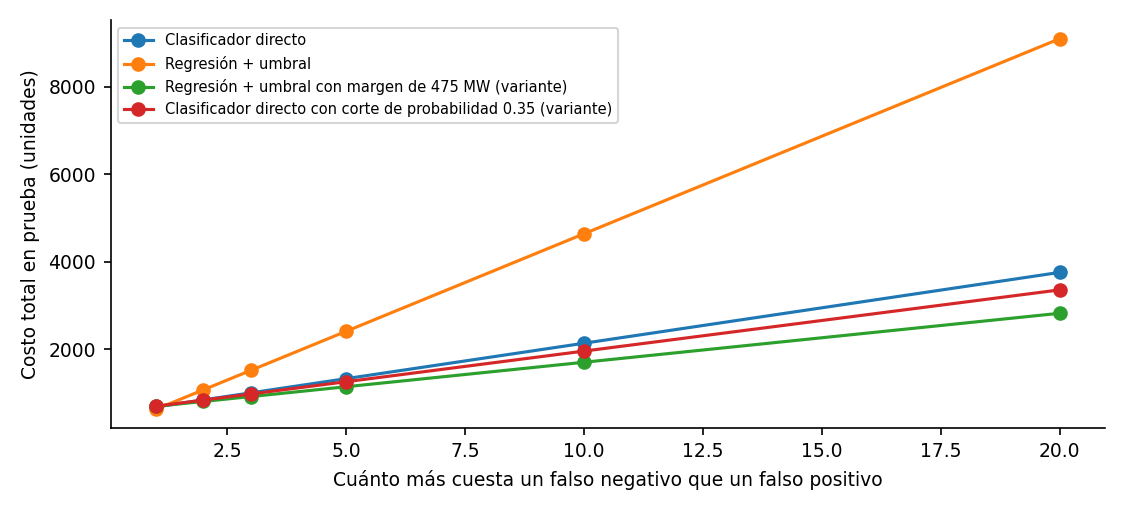

,Clasificador directo,Regresión + umbral,Regresión + umbral con margen de 475 MW (variante),Clasificador directo con corte de probabilidad 0.35 (variante),Menor costo
FN cuesta N veces un FP,,,,,
1,679.0,626.0,694.0,697.0,Regresión + umbral
2,841.0,1072.0,806.0,837.0,Regresión + umbral con margen de 475 MW (varia...
3,1003.0,1518.0,918.0,977.0,Regresión + umbral con margen de 475 MW (varia...
5,1327.0,2410.0,1142.0,1257.0,Regresión + umbral con margen de 475 MW (varia...
10,2137.0,4640.0,1702.0,1957.0,Regresión + umbral con margen de 475 MW (varia...
20,3757.0,9100.0,2822.0,3357.0,Regresión + umbral con margen de 475 MW (varia...


In [22]:
# Sensibilidad al cociente de costos FN/FP (los sistemas y las variantes quedan fijos).
RATIOS = [1, 2, 3, 5, 10, 20]
filas = []
for r in RATIOS:
    fila = {'FN cuesta N veces un FP': r}
    for nombre, a in sistemas.items():
        fila[nombre] = costo(met_clf(yte_c, a), r)
    fila['Menor costo'] = min(sistemas, key=lambda s: fila[s])
    filas.append(fila)
tab_sens = pd.DataFrame(filas).set_index('FN cuesta N veces un FP')
RES34['sensibilidad_costos_test'] = {int(r): {c: (float(v) if c != 'Menor costo' else v) for c, v in fila.items()} for r, fila in tab_sens.iterrows()}

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for nombre in sistemas:
    ax.plot(tab_sens.index, tab_sens[nombre], 'o-', label=nombre)
ax.set_xlabel('Cuánto más cuesta un falso negativo que un falso positivo'); ax.set_ylabel('Costo total en prueba (unidades)')
ax.legend(fontsize=7); guardar(fig, 'fig8_sensibilidad_costos.png')
tab_sens.round(0)

**Lectura.** El resultado depende del esquema de costos. Si un FP y un FN costaran lo mismo (1 a 1), la regresión + umbral sería la de menor costo (626 contra 679). Desde que el FN cuesta el doble, el clasificador directo pasa a ser mejor que la regresión + umbral con el umbral fijo (841 contra 1.072). Con cocientes de 2 a 20, la variante con margen es la de menor costo. Antes de usar el sistema hay que **confirmar con la operación cuánto más grave es un pico no anticipado**.

### 12.3 Casos cercanos al umbral

In [23]:
ev = te.assign(pred=pred_te, a_dir=alerta_dir_te, a_reg=alerta_reg_te)
ev['dist_real'] = (ev.DemGBA - UMBRAL).abs()
ev['err_dir'] = ev.a_dir != ev.alta_demanda
ev['err_reg'] = ev.a_reg != ev.alta_demanda
ev['banda'] = pd.cut(ev.dist_real, [-1, 300, 800, np.inf], labels=['a menos de 300 MW del umbral', 'entre 300 y 800 MW', 'a más de 800 MW'])
tab_cerca = ev.groupby('banda', observed=True).agg(horas=('err_dir', 'size'), errores_directo=('err_dir', 'sum'),
                                                   errores_reg_umbral=('err_reg', 'sum'))
tab_cerca['% error directo'] = tab_cerca.errores_directo / tab_cerca.horas * 100
tab_cerca['% error reg+umbral'] = tab_cerca.errores_reg_umbral / tab_cerca.horas * 100
RES34['errores_por_cercania_umbral_test'] = {k: {c: float(v) for c, v in r.items()} for k, r in tab_cerca.iterrows()}
display(tab_cerca.round(1))

# ¿Buen MAE y mala clasificación?
mae_t = float(mean_absolute_error(yte, pred_te))
buen_mae_mal_alerta = ev[(np.abs(ev.DemGBA - ev.pred) <= mae_t) & ev.err_reg]
print(f'Horas con error numérico menor o igual al MAE ({mae_t:.0f} MW) y alerta equivocada (regresión + umbral): '
      f'{len(buen_mae_mal_alerta)} de {int(ev.err_reg.sum())} errores de alerta '
      f'({len(buen_mae_mal_alerta) / ev.err_reg.sum() * 100:.0f} %).')
print('Distancia media de esos casos al umbral:', round(float(buen_mae_mal_alerta.dist_real.mean())), 'MW')
RES34['buen_mae_mala_alerta'] = {'casos': int(len(buen_mae_mal_alerta)), 'errores_alerta_reg': int(ev.err_reg.sum()),
                                 'dist_media_umbral_MW': float(buen_mae_mal_alerta.dist_real.mean())}

# Coincidencia y desacuerdo entre los dos sistemas
coinciden = ev.a_dir == ev.a_reg
des = ev[~coinciden]
print(f'Los dos sistemas coinciden en {int(coinciden.sum())} de {len(ev)} horas ({coinciden.mean() * 100:.1f} %).')
print(f'En los {len(des)} desacuerdos: acierta el directo {int((des.a_dir == des.alta_demanda).sum())} veces '
      f'y acierta regresión + umbral {int((des.a_reg == des.alta_demanda).sum())} veces.')
RES34['coincidencia_test'] = {'coinciden': int(coinciden.sum()), 'total': int(len(ev)), 'desacuerdos': int(len(des)),
                              'acierta_directo': int((des.a_dir == des.alta_demanda).sum()),
                              'acierta_reg': int((des.a_reg == des.alta_demanda).sum())}

,horas,errores_directo,errores_reg_umbral,% error directo,% error reg+umbral
banda,,,,,
a menos de 300 MW del umbral,712,292,313,41.0,44.0
entre 300 y 800 MW,1195,228,251,19.1,21.0
a más de 800 MW,6853,159,62,2.3,0.9


Horas con error numérico menor o igual al MAE (413 MW) y alerta equivocada (regresión + umbral): 136 de 626 errores de alerta (22 %).
Distancia media de esos casos al umbral: 138 MW
Los dos sistemas coinciden en 8089 de 8760 horas (92.3 %).
En los 671 desacuerdos: acierta el directo 309 veces y acierta regresión + umbral 362 veces.


**Lectura.**
- **Los errores se concentran junto al umbral.** A menos de 300 MW del umbral, el 41 % (directo) y el 44 % (regresión + umbral) de las alertas son incorrectas; a más de 800 MW, solo el 2,3 % y el 0,9 %. El 90 % de los errores de alerta de la regresión + umbral ocurre a menos de 800 MW del umbral.
- **Un buen MAE no garantiza una buena alerta.** En 136 de los 626 errores de alerta de la regresión + umbral (22 %), el error numérico era menor o igual al MAE (413 MW). La distancia media de esos casos al umbral es de solo 138 MW. Para el operador la alerta es incorrecta aunque la estimación sea buena.
- **Los dos sistemas coinciden en el 92,3 % de las horas.** En los 671 desacuerdos, acierta el clasificador directo 309 veces y la regresión + umbral 362 veces. Por eso la aplicación muestra los dos resultados y avisa cuando no coinciden.

### 12.4 Casos concretos de falsos negativos y falsos positivos (regresión + umbral)

In [24]:
cols = ['datetime', 'DemGBA', 'pred', 'Temp', 'hora', 'Holiday']
nombres = ['Fecha y hora', 'Real (MW)', 'Predicho (MW)', 'Temp (°C)', 'Hora', 'Feriado']
fn = ev[(ev.a_reg == 0) & (ev.alta_demanda == 1)].nlargest(5, 'DemGBA')[cols]; fn.columns = nombres
fp = ev[(ev.a_reg == 1) & (ev.alta_demanda == 0)].nlargest(5, 'pred')[cols]; fp.columns = nombres
fn['Real − umbral (MW)'] = fn['Real (MW)'] - UMBRAL; fp['Real − umbral (MW)'] = fp['Real (MW)'] - UMBRAL
print('Falsos negativos de regresión + umbral (los 5 de mayor demanda real):'); display(fn.round(0))
print('Falsos positivos de regresión + umbral (las 5 mayores predicciones):'); display(fp.round(0))
RES34['casos_fn_reg'] = [{k: (str(v) if k == 'Fecha y hora' else float(v)) for k, v in r.items()} for _, r in fn.iterrows()]
RES34['casos_fp_reg'] = [{k: (str(v) if k == 'Fecha y hora' else float(v)) for k, v in r.items()} for _, r in fp.iterrows()]
fn_hora = ev[(ev.a_reg == 0) & (ev.alta_demanda == 1)].hora.value_counts().sort_index()
print('Falsos negativos por hora (regresión + umbral):', {int(h): int(v) for h, v in fn_hora.items()})

Falsos negativos de regresión + umbral (los 5 de mayor demanda real):


,Fecha y hora,Real (MW),Predicho (MW),Temp (°C),Hora,Feriado,Real − umbral (MW)
53345,2018-01-31 17:00:00,8790,7204.0,31.0,17,0,1483.0
53544,2018-02-09 00:00:00,8717,7108.0,28.0,0,0,1410.0
52889,2018-01-12 17:00:00,8690,7199.0,30.0,17,0,1383.0
53152,2018-01-23 16:00:00,8591,7199.0,29.0,16,0,1284.0
53393,2018-02-02 17:00:00,8573,7119.0,28.0,17,0,1266.0


Falsos positivos de regresión + umbral (las 5 mayores predicciones):


,Fecha y hora,Real (MW),Predicho (MW),Temp (°C),Hora,Feriado,Real − umbral (MW)
54208,2018-03-08 16:00:00,6837,8632.0,30.0,16,0,-470.0
54228,2018-03-09 12:00:00,6931,8632.0,29.0,12,0,-376.0
54325,2018-03-13 13:00:00,6376,8632.0,29.0,13,0,-931.0
54326,2018-03-13 14:00:00,6450,8632.0,29.0,14,0,-857.0
54327,2018-03-13 15:00:00,6527,8632.0,31.0,15,0,-780.0


Falsos negativos por hora (regresión + umbral): {0: 45, 1: 21, 2: 4, 3: 2, 8: 19, 9: 27, 10: 27, 11: 11, 12: 16, 13: 19, 14: 15, 15: 19, 16: 36, 17: 34, 18: 30, 19: 25, 20: 22, 21: 28, 22: 25, 23: 21}


**Lectura.**
- **Falsos negativos:** los cinco peores son días calurosos (28–31 °C) de enero y febrero de 2018, con demandas reales de 8.600 a 8.800 MW. El modelo predijo unos 7.100–7.200 MW, apenas por debajo del umbral. Consecuencia: pico sin reserva preparada. El modelo subestima los picos extremos, como pasa con los modelos que tienden hacia el promedio.
- **Falsos positivos:** son días de marzo de 2018 con 29–31 °C en los que el modelo predijo 8.632 MW y la demanda real fue de 6.400 a 6.900 MW. Consecuencia: reserva activada sin necesidad.
- Los falsos negativos de la regresión + umbral aparecen a lo largo del día, con máximos a las 0 h (45 casos) y entre las 16 y las 18 h (100 casos entre las tres horas).

### 12.5 Gráficos de la integración

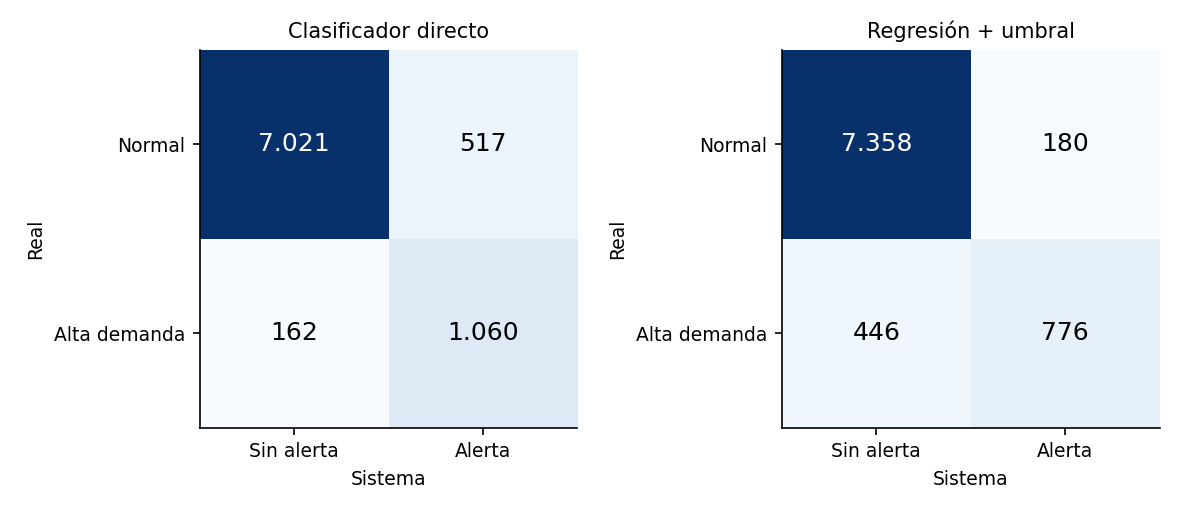

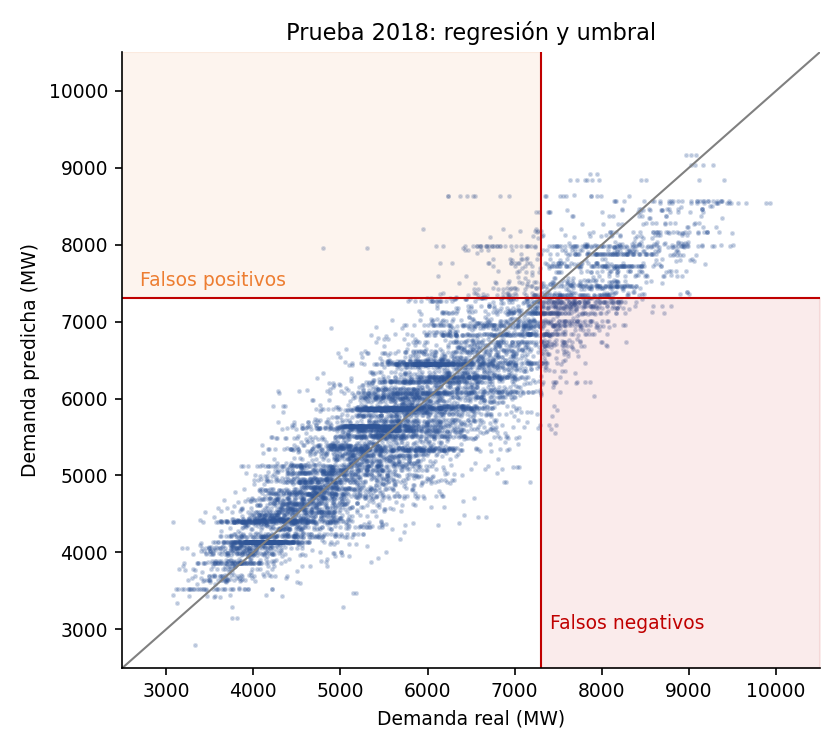

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3.4))
for ax, (nombre, a) in zip(axs, list(sistemas.items())[:2]):
    cm = confusion_matrix(yte_c, a, labels=[0, 1])
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}'.replace(',', '.'), ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=12)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Sin alerta', 'Alerta']); ax.set_yticks([0, 1]); ax.set_yticklabels(['Normal', 'Alta demanda'])
    ax.set_xlabel('Sistema'); ax.set_ylabel('Real'); ax.set_title(nombre, fontsize=10)
guardar(fig, 'fig7_matrices_confusion.png')

fig, ax = plt.subplots(figsize=(5.6, 5))
ax.scatter(ev.DemGBA, ev.pred, s=2, alpha=0.2, color='#2F5597')
lim = [2500, 10500]; ax.plot(lim, lim, color='gray', lw=1)
ax.axvline(UMBRAL, color='#C00000', lw=1); ax.axhline(UMBRAL, color='#C00000', lw=1)
ax.fill_between([UMBRAL, lim[1]], lim[0], UMBRAL, color='#C00000', alpha=0.08)
ax.fill_between([lim[0], UMBRAL], UMBRAL, lim[1], color='#ED7D31', alpha=0.08)
ax.text(UMBRAL + 100, 3000, 'Falsos negativos', color='#C00000', fontsize=9)
ax.text(2700, UMBRAL + 150, 'Falsos positivos', color='#ED7D31', fontsize=9)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel('Demanda real (MW)'); ax.set_ylabel('Demanda predicha (MW)')
ax.set_title('Prueba 2018: regresión y umbral')
guardar(fig, 'fig9_real_vs_predicho.png')

### 12.6 Modelos guardados y verificación
Se guardan los dos Pipelines elegidos con `joblib` y un archivo `metadatos.json` con el umbral, el orden de los predictores, los rangos de entrenamiento, los costos, las versiones de las librerías y la semilla. La aplicación Flask **solo carga estos archivos y ejecuta `predict`**: no entrena.

Los Pipelines guardados son **los mismos que se evalúan en este notebook** (entrenados con 2012–2016). Si se vuelve a ejecutar el notebook, hay que usar las versiones de `requirements-notebook.txt`; si no, `joblib` puede no poder cargar los modelos.

In [26]:
MODELOS = '../modelos'
os.makedirs(MODELOS, exist_ok=True)
joblib.dump(REG, f'{MODELOS}/regresor.joblib', compress=3)
joblib.dump(CLF, f'{MODELOS}/clasificador.joblib', compress=3)

meta = {
    'umbral_MW': UMBRAL,
    'predictores': BASE,
    'rangos_entrenamiento': {c: [float(tr[c].min()), float(tr[c].max())] for c in BASE},
    'costo_fn_sobre_fp': COSTO_FN,
    'margen_precaucion_MW': MARGEN,
    'regresor': NOM_REG,
    'clasificador': NOM_CLF,
    'mae_test_MW': mae_t,
    'semilla': SEED,
    'versiones': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                  'scikit-learn': sklearn.__version__, 'joblib': joblib.__version__},
}
with open(f'{MODELOS}/metadatos.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
RES34['metadatos'] = meta
with open(f'{SALIDA}/resultados_entrega3_4.json', 'w', encoding='utf-8') as f:
    json.dump(RES34, f, ensure_ascii=False, indent=2)

# Verificación: los modelos guardados dan exactamente las mismas predicciones.
reg2, clf2 = joblib.load(f'{MODELOS}/regresor.joblib'), joblib.load(f'{MODELOS}/clasificador.joblib')
assert np.allclose(reg2.predict(Xte), pred_te) and (clf2.predict(Xte) == alerta_dir_te).all()
print('Modelos guardados en ../modelos/ y verificados. Versiones:', meta['versiones'])

Modelos guardados en ../modelos/ y verificados. Versiones: {'python': '3.12.3', 'numpy': '2.4.4', 'pandas': '3.0.2', 'scikit-learn': '1.8.0', 'joblib': '1.5.3'}


## 13. Respuestas a las preguntas del informe

1. **¿El modelo de regresión supera al baseline?** Sí. En prueba, MAE 413 MW contra 1.019 (`DummyRegressor`) y 611 (referencia estacional); R² 0,825 contra −0,001 y 0,644.
2. **¿Qué significa el MAE en este contexto?** En promedio la estimación se desvía 413 MW de la demanda real: el 7,1 % de la demanda media y el 5,7 % del umbral. Es relevante para una alerta cuyo umbral es 7.307 MW.
3. **¿Qué modelo detecta mejor los casos críticos?** El clasificador directo (árbol de profundidad 8 con pesos 1:5): recall 0,87. Le siguen `GaussianNB` (0,64), la regresión + umbral (0,64), KNN (0,57) y la referencia estacional (0,24).
4. **¿Qué errores son más costosos?** Los falsos negativos (pico no anticipado), que se valoraron 5 veces más que un falso positivo. Es un supuesto: con costos iguales el orden de los sistemas cambia (sección 12.2).
5. **¿Qué sucede con los casos cercanos al umbral?** Es donde fallan ambos sistemas: 41–44 % de error a menos de 300 MW del umbral y 1–2 % a más de 800 MW.
6. **¿Es posible obtener un buen MAE y una mala clasificación?** Sí. Con MAE de 413 MW, la regresión + umbral deja sin detectar el 36 % de los picos (recall 0,64), y el 22 % de sus errores de alerta tiene un error numérico menor que el MAE.
7. **¿Qué sistema recomendarían y por qué?** Con costos 1:5, el **clasificador directo** como alerta principal, porque detecta más picos (recall 0,87) y tiene un costo 45 % menor que la regresión + umbral con el umbral fijo. La **regresión** se usa para informar los MW esperados y como control cruzado: si los dos sistemas no coinciden, hay que revisar el caso. La regresión con margen de precaución es una alternativa equivalente que conviene validar con más años de datos.
8. **¿En qué situaciones no debería utilizarse la solución?** Con datos fuera del rango de entrenamiento; ante días atípicos que el calendario no marca (puentes, eventos, cortes); con pronósticos meteorológicos de mala calidad (el entrenamiento usó mediciones); para otra región distinta del GBA; si los costos reales de FP y FN son muy distintos de los supuestos; y como único criterio para decidir la seguridad del suministro.